In [ ]:

# 資料處理與視覺化
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 資料集
from sklearn.datasets import load_iris, make_circles

# 資料前處理
from sklearn.preprocessing import StandardScaler

# 分群演算法
from sklearn.cluster import (
    KMeans,
    DBSCAN,
    AgglomerativeClustering
)

# 分群評估指標
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

# 超參數調校
from sklearn.model_selection import ParameterGrid


# 視覺化工具
from sklearn.decomposition import PCA


In [ ]:
# 載入 Iris 資料集
iris_cluster = load_iris()

# 特徵資料與真實標籤
iris_cluster_X = iris_cluster.data
iris_cluster_y = iris_cluster.target

# 特徵標準化
iris_scaler = StandardScaler()
iris_cluster_X_scaled = iris_scaler.fit_transform(iris_cluster_X)

# 查看資料集資訊
print("=== Iris 分群資料集 ===")
print("資料筆數：", iris_cluster_X.shape[0])
print("特徵數量：", iris_cluster_X.shape[1])
print("特徵名稱：", iris_cluster.feature_names)
print("真實類別：", iris_cluster.target_names)

print("\n標準化後資料形狀：", iris_cluster_X_scaled.shape)


=== Iris 分群資料集 ===
資料筆數： 150
特徵數量： 4
特徵名稱： ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
真實類別： ['setosa' 'versicolor' 'virginica']

標準化後資料形狀： (150, 4)


In [ ]:
# 建立同心圓模擬資料
circles_X, circles_y = make_circles(
    n_samples=500,
    noise=0.05,
    factor=0.5,
    random_state=42
)

# 特徵標準化
circles_scaler = StandardScaler()
circles_X_scaled = circles_scaler.fit_transform(circles_X)

# 查看資料集資訊
print("=== make_circles 分群資料集 ===")
print("資料筆數：", circles_X.shape[0])
print("特徵數量：", circles_X.shape[1])
print("群集類別數量：", len(np.unique(circles_y)))

print("\n標準化後資料形狀：", circles_X_scaled.shape)


=== make_circles 分群資料集 ===
資料筆數： 500
特徵數量： 2
群集類別數量： 2

標準化後資料形狀： (500, 2)


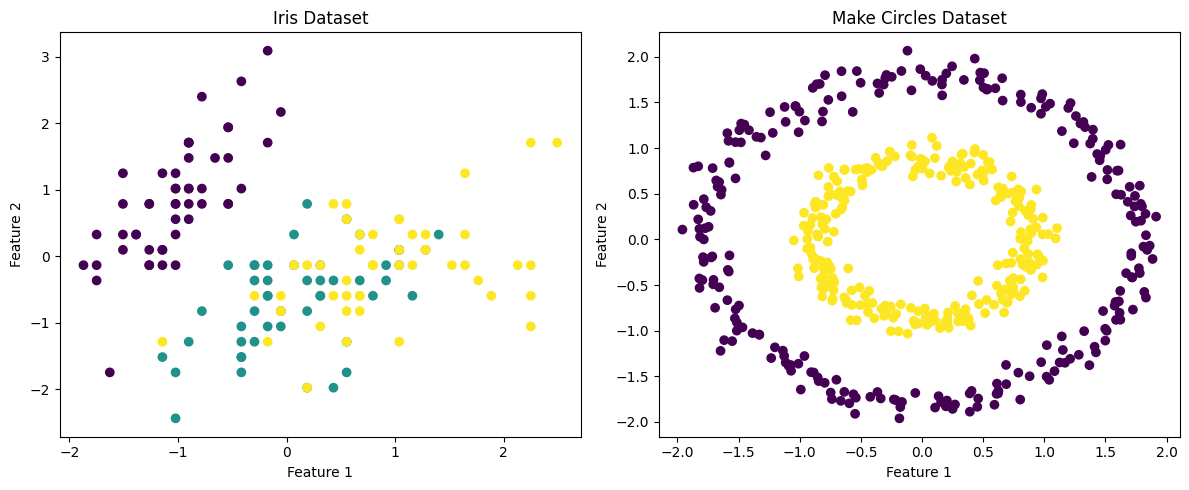

In [ ]:
#原始分布圖
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Iris：使用前兩個特徵呈現資料分布
axes[0].scatter(
    iris_cluster_X_scaled[:, 0],
    iris_cluster_X_scaled[:, 1],
    c=iris_cluster_y,
    cmap="viridis"
)
axes[0].set_title("Iris Dataset")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")

# make_circles：呈現同心圓分布
axes[1].scatter(
    circles_X_scaled[:, 0],
    circles_X_scaled[:, 1],
    c=circles_y,
    cmap="viridis"
)
axes[1].set_title("Make Circles Dataset")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")

plt.tight_layout()
plt.show()


In [ ]:

# 分群演算法設定

# KMeans
kmeans_iris = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_circles = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# DBSCAN
dbscan_iris = DBSCAN(
    eps=0.8,
    min_samples=5
)

dbscan_circles = DBSCAN(
    eps=0.2,
    min_samples=5
)

# Agglomerative Clustering
agg_iris = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

agg_circles = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

In [ ]:
# 執行分群

# Iris 資料集
iris_kmeans_labels = kmeans_iris.fit_predict(iris_cluster_X_scaled)
iris_dbscan_labels = dbscan_iris.fit_predict(iris_cluster_X_scaled)
iris_agg_labels = agg_iris.fit_predict(iris_cluster_X_scaled)

# make_circles 資料集
circles_kmeans_labels = kmeans_circles.fit_predict(circles_X_scaled)
circles_dbscan_labels = dbscan_circles.fit_predict(circles_X_scaled)
circles_agg_labels = agg_circles.fit_predict(circles_X_scaled)

In [ ]:
# 分群結果統計

# 建立結果列表
cluster_results = {
    "Iris": {
        "KMeans": iris_kmeans_labels,
        "DBSCAN": iris_dbscan_labels,
        "Agglomerative": iris_agg_labels
    },
    "make_circles": {
        "KMeans": circles_kmeans_labels,
        "DBSCAN": circles_dbscan_labels,
        "Agglomerative": circles_agg_labels
    }
}

# 統計群集數量與雜訊數量
for dataset_name, models in cluster_results.items():
    print(f"\n=== {dataset_name} 分群結果 ===")

    for model_name, labels in models.items():
        cluster_count = len(set(labels) - {-1})
        noise_count = np.sum(labels == -1)

        print(
            f"{model_name}: "
            f"群集數量 = {cluster_count}, "
            f"雜訊數量 = {noise_count}"
        )



=== Iris 分群結果 ===
KMeans: 群集數量 = 3, 雜訊數量 = 0
DBSCAN: 群集數量 = 2, 雜訊數量 = 4
Agglomerative: 群集數量 = 3, 雜訊數量 = 0

=== make_circles 分群結果 ===
KMeans: 群集數量 = 2, 雜訊數量 = 0
DBSCAN: 群集數量 = 5, 雜訊數量 = 3
Agglomerative: 群集數量 = 2, 雜訊數量 = 0


In [ ]:
# PCA 降維

iris_pca = PCA(n_components=2)
iris_cluster_2d = iris_pca.fit_transform(iris_cluster_X_scaled)

print("Iris PCA 降維完成！")
print("原始特徵數量：", iris_cluster_X_scaled.shape[1])
print("降維後特徵數量：", iris_cluster_2d.shape[1])
print("累積解釋變異比例：", iris_pca.explained_variance_ratio_.sum())


Iris PCA 降維完成！
原始特徵數量： 4
降維後特徵數量： 2
累積解釋變異比例： 0.9581320720000166


In [ ]:

# 分群評估

# 建立評估函式
def evaluate_clustering(X, labels, true_labels):
    # 排除 DBSCAN 的雜訊點
    valid_mask = labels != -1
    valid_X = X[valid_mask]
    valid_labels = labels[valid_mask]

    # 計算群集數量
    n_clusters = len(set(labels) - {-1})

    # 計算評估指標
    if n_clusters >= 2 and n_clusters < len(valid_labels):
        silhouette = silhouette_score(valid_X, valid_labels)
        davies_bouldin = davies_bouldin_score(valid_X, valid_labels)
        calinski_harabasz = calinski_harabasz_score(valid_X, valid_labels)
    else:
        silhouette = np.nan
        davies_bouldin = np.nan
        calinski_harabasz = np.nan

    # 計算 ARI
    ari = adjusted_rand_score(true_labels, labels)

    return {
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": davies_bouldin,
        "Calinski-Harabasz Index": calinski_harabasz,
        "ARI": ari
    }


# 建立評估結果
clustering_results = []

# Iris 資料集
for model_name, labels in [
    ("KMeans", iris_kmeans_labels),
    ("DBSCAN", iris_dbscan_labels),
    ("Agglomerative", iris_agg_labels)
]:
    scores = evaluate_clustering(
        iris_cluster_X_scaled,
        labels,
        iris_cluster_y
    )

    clustering_results.append({
        "Dataset": "Iris",
        "Algorithm": model_name,
        **scores
    })


# make_circles 資料集
for model_name, labels in [
    ("KMeans", circles_kmeans_labels),
    ("DBSCAN", circles_dbscan_labels),
    ("Agglomerative", circles_agg_labels)
]:
    scores = evaluate_clustering(
        circles_X_scaled,
        labels,
        circles_y
    )

    clustering_results.append({
        "Dataset": "make_circles",
        "Algorithm": model_name,
        **scores
    })


# 顯示評估結果
clustering_df = pd.DataFrame(clustering_results)

print("=== 分群評估結果 ===")
display(clustering_df.round(4))


=== 分群評估結果 ===


,Dataset,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,ARI
0,Iris,KMeans,0.4599,0.8336,241.9044,0.6201
1,Iris,DBSCAN,0.5979,0.5688,277.6510,0.5518
2,Iris,Agglomerative,0.4467,0.8035,222.7192,0.6153
3,make_circles,KMeans,0.3531,1.1825,287.0803,-0.0020
4,make_circles,DBSCAN,0.1231,1.1738,117.1070,0.6798
5,make_circles,Agglomerative,0.3451,1.2065,275.2463,0.0058


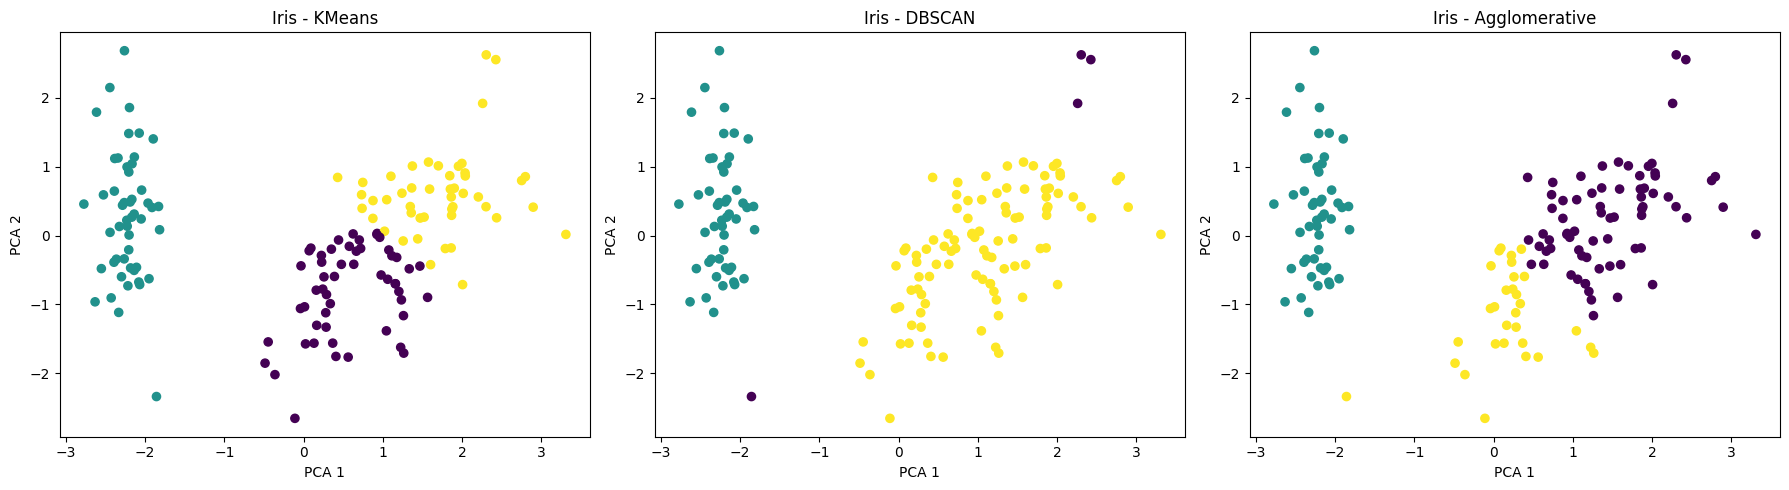

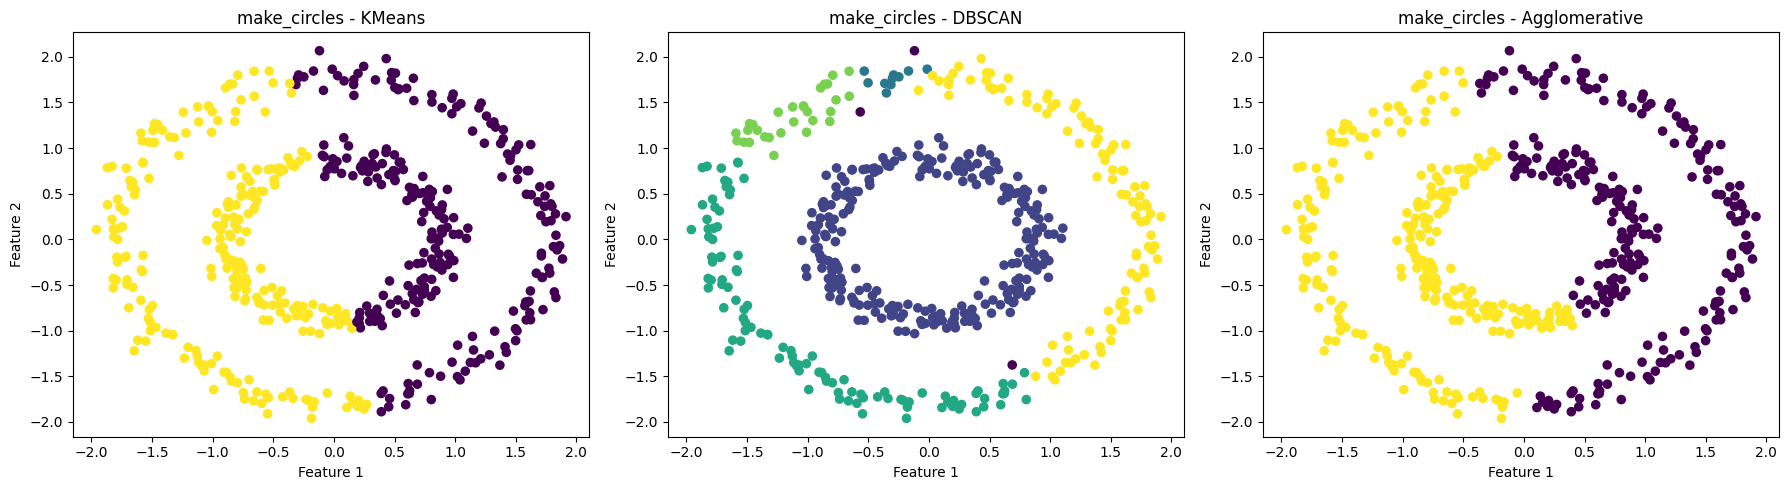

In [ ]:

# 分群結果視覺化

# Iris 資料集 PCA 降維
iris_pca = PCA(n_components=2)
iris_cluster_2d = iris_pca.fit_transform(iris_cluster_X_scaled)

# Iris 分群結果
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

iris_labels_list = [
    ("KMeans", iris_kmeans_labels),
    ("DBSCAN", iris_dbscan_labels),
    ("Agglomerative", iris_agg_labels)
]

for ax, (model_name, labels) in zip(axes, iris_labels_list):
    ax.scatter(
        iris_cluster_2d[:, 0],
        iris_cluster_2d[:, 1],
        c=labels,
        cmap="viridis",
        s=35
    )
    ax.set_title(f"Iris - {model_name}")
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")

plt.tight_layout()
plt.show()


# make_circles 分群結果
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

circles_labels_list = [
    ("KMeans", circles_kmeans_labels),
    ("DBSCAN", circles_dbscan_labels),
    ("Agglomerative", circles_agg_labels)
]

for ax, (model_name, labels) in zip(axes, circles_labels_list):
    ax.scatter(
        circles_X_scaled[:, 0],
        circles_X_scaled[:, 1],
        c=labels,
        cmap="viridis",
        s=35
    )
    ax.set_title(f"make_circles - {model_name}")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()


In [ ]:
# 超參數調校設定
# KMeans 參數
kmeans_param_grid = {
    "n_clusters": [2, 3, 4, 5],
    "n_init": [10, 20]
}

# DBSCAN 參數
dbscan_param_grid = {
    "eps": [0.1, 0.2, 0.3, 0.5, 0.8],
    "min_samples": [3, 5, 10]
}

# Agglomerative 參數
agg_param_grid = {
    "n_clusters": [2, 3, 4, 5],
    "linkage": ["ward", "complete", "average"]
}

In [ ]:

# 超參數搜尋函式
def clustering_grid_search(X, y, algorithm, param_grid, true_labels):

    # 儲存搜尋結果
    results = []

    # 產生所有參數組合
    for params in ParameterGrid(param_grid):

        # 建立分群模型
        if algorithm == "KMeans":
            model = KMeans(
                **params,
                random_state=42
            )

        elif algorithm == "DBSCAN":
            model = DBSCAN(**params)

        elif algorithm == "Agglomerative":
            model = AgglomerativeClustering(**params)

        # 執行分群
        labels = model.fit_predict(X)

        # 排除雜訊點
        valid_mask = labels != -1
        valid_X = X[valid_mask]
        valid_labels = labels[valid_mask]

        # 計算群集數量
        n_clusters = len(set(labels) - {-1})

        # 計算評估指標
        if 2 <= n_clusters < len(valid_labels):
            silhouette = silhouette_score(
                valid_X,
                valid_labels
            )
            ari = adjusted_rand_score(true_labels, labels)
        else:
            silhouette = np.nan
            ari = adjusted_rand_score(true_labels, labels)

        # 儲存結果
        results.append({
            "Algorithm": algorithm,
            "Parameters": params,
            "Clusters": n_clusters,
            "Noise": np.sum(labels == -1),
            "Silhouette Score": silhouette,
            "ARI": ari
        })

    # 整理搜尋結果
    results_df = pd.DataFrame(results)

    # 依照 Silhouette Score 排序
    results_df = results_df.sort_values(
        by="Silhouette Score",
        ascending=False,
        na_position="last"
    )

    return results_df



In [ ]:

# 執行超參數調校

# Iris 資料集
iris_kmeans_tuning = clustering_grid_search(
    iris_cluster_X_scaled,
    iris_cluster_y,
    "KMeans",
    kmeans_param_grid,
    iris_cluster_y
)

iris_dbscan_tuning = clustering_grid_search(
    iris_cluster_X_scaled,
    iris_cluster_y,
    "DBSCAN",
    dbscan_param_grid,
    iris_cluster_y
)

iris_agg_tuning = clustering_grid_search(
    iris_cluster_X_scaled,
    iris_cluster_y,
    "Agglomerative",
    agg_param_grid,
    iris_cluster_y
)


# make_circles 資料集
circles_kmeans_tuning = clustering_grid_search(
    circles_X_scaled,
    circles_y,
    "KMeans",
    kmeans_param_grid,
    circles_y
)

circles_dbscan_tuning = clustering_grid_search(
    circles_X_scaled,
    circles_y,
    "DBSCAN",
    dbscan_param_grid,
    circles_y
)

circles_agg_tuning = clustering_grid_search(
    circles_X_scaled,
    circles_y,
    "Agglomerative",
    agg_param_grid,
    circles_y
)

In [ ]:
# 顯示最佳調校結果

# Iris 資料集
print("=== Iris 最佳調校結果 ===")

for model_name, result in [
    ("KMeans", iris_kmeans_tuning),
    ("DBSCAN", iris_dbscan_tuning),
    ("Agglomerative", iris_agg_tuning)
]:
    print(f"\n{model_name}")
    display(result.head(1))


# make_circles 資料集
print("=== make_circles 最佳調校結果 ===")

for model_name, result in [
    ("KMeans", circles_kmeans_tuning),
    ("DBSCAN", circles_dbscan_tuning),
    ("Agglomerative", circles_agg_tuning)
]:
    print(f"\n{model_name}")
    display(result.head(1))


=== Iris 最佳調校結果 ===

KMeans


,Algorithm,Parameters,Clusters,Noise,Silhouette Score,ARI
0,KMeans,"{'n_clusters': 2, 'n_init': 10}",2,0,0.58175,0.568116



DBSCAN


,Algorithm,Parameters,Clusters,Noise,Silhouette Score,ARI
11,DBSCAN,"{'eps': 0.5, 'min_samples': 10}",3,89,0.710088,0.279191



Agglomerative


,Algorithm,Parameters,Clusters,Noise,Silhouette Score,ARI
8,Agglomerative,"{'linkage': 'average', 'n_clusters': 2}",2,0,0.58175,0.568116


... (2 outputs left out)


DBSCAN


,Algorithm,Parameters,Clusters,Noise,Silhouette Score,ARI
1,DBSCAN,"{'eps': 0.1, 'min_samples': 5}",24,247,0.489375,0.226746



Agglomerative


,Algorithm,Parameters,Clusters,Noise,Silhouette Score,ARI
9,Agglomerative,"{'linkage': 'average', 'n_clusters': 3}",3,0,0.358943,0.006845


In [ ]:

# 超參數調校前後比較

# 原始模型結果
before_results = clustering_df.copy()

# 最佳調校結果
tuning_results = {
    "Iris": {
        "KMeans": iris_kmeans_tuning,
        "DBSCAN": iris_dbscan_tuning,
        "Agglomerative": iris_agg_tuning
    },
    "make_circles": {
        "KMeans": circles_kmeans_tuning,
        "DBSCAN": circles_dbscan_tuning,
        "Agglomerative": circles_agg_tuning
    }
}

# 整理比較資料
comparison_results = []

for dataset_name, models in tuning_results.items():

    for model_name, result in models.items():

        # 找出最佳參數組合
        best_result = result.dropna(
            subset=["Silhouette Score"]
        ).iloc[0]

        # 取得調校前結果
        before = before_results[
            (before_results["Dataset"] == dataset_name) &
            (before_results["Algorithm"] == model_name)
        ].iloc[0]

        comparison_results.append({
            "Dataset": dataset_name,
            "Algorithm": model_name,
            "Before Silhouette": before["Silhouette Score"],
            "After Silhouette": best_result["Silhouette Score"],
            "Before ARI": before["ARI"],
            "After ARI": best_result["ARI"],
            "Best Parameters": best_result["Parameters"],
            "Best Clusters": best_result["Clusters"],
            "Best Noise": best_result["Noise"]
        })

# 建立比較表
comparison_df = pd.DataFrame(comparison_results)

print("=== 超參數調校前後比較 ===")
display(comparison_df.round(4))


=== 超參數調校前後比較 ===


,Dataset,Algorithm,Before Silhouette,After Silhouette,Before ARI,After ARI,Best Parameters,Best Clusters,Best Noise
0,Iris,KMeans,0.4599,0.5818,0.6201,0.5681,"{'n_clusters': 2, 'n_init': 10}",2,0
1,Iris,DBSCAN,0.5979,0.7101,0.5518,0.2792,"{'eps': 0.5, 'min_samples': 10}",3,89
2,Iris,Agglomerative,0.4467,0.5818,0.6153,0.5681,"{'linkage': 'average', 'n_clusters': 2}",2,0
3,make_circles,KMeans,0.3531,0.3885,-0.0020,-0.0026,"{'n_clusters': 3, 'n_init': 20}",3,0
4,make_circles,DBSCAN,0.1231,0.4894,0.6798,0.2267,"{'eps': 0.1, 'min_samples': 5}",24,247
5,make_circles,Agglomerative,0.3451,0.3589,0.0058,0.0068,"{'linkage': 'average', 'n_clusters': 3}",3,0


In [ ]:

# 取得最佳模型參數

# Iris 資料集
iris_best_models = {
    "KMeans": KMeans(
        **iris_kmeans_tuning.dropna(
            subset=["Silhouette Score"]
        ).iloc[0]["Parameters"],
        random_state=42
    ),
    "DBSCAN": DBSCAN(
        **iris_dbscan_tuning.dropna(
            subset=["Silhouette Score"]
        ).iloc[0]["Parameters"]
    ),
    "Agglomerative": AgglomerativeClustering(
        **iris_agg_tuning.dropna(
            subset=["Silhouette Score"]
        ).iloc[0]["Parameters"]
    )
}

# make_circles 資料集
circles_best_models = {
    "KMeans": KMeans(
        **circles_kmeans_tuning.dropna(
            subset=["Silhouette Score"]
        ).iloc[0]["Parameters"],
        random_state=42
    ),
    "DBSCAN": DBSCAN(
        **circles_dbscan_tuning.dropna(
            subset=["Silhouette Score"]
        ).iloc[0]["Parameters"]
    ),
    "Agglomerative": AgglomerativeClustering(
        **circles_agg_tuning.dropna(
            subset=["Silhouette Score"]
        ).iloc[0]["Parameters"]
    )
}

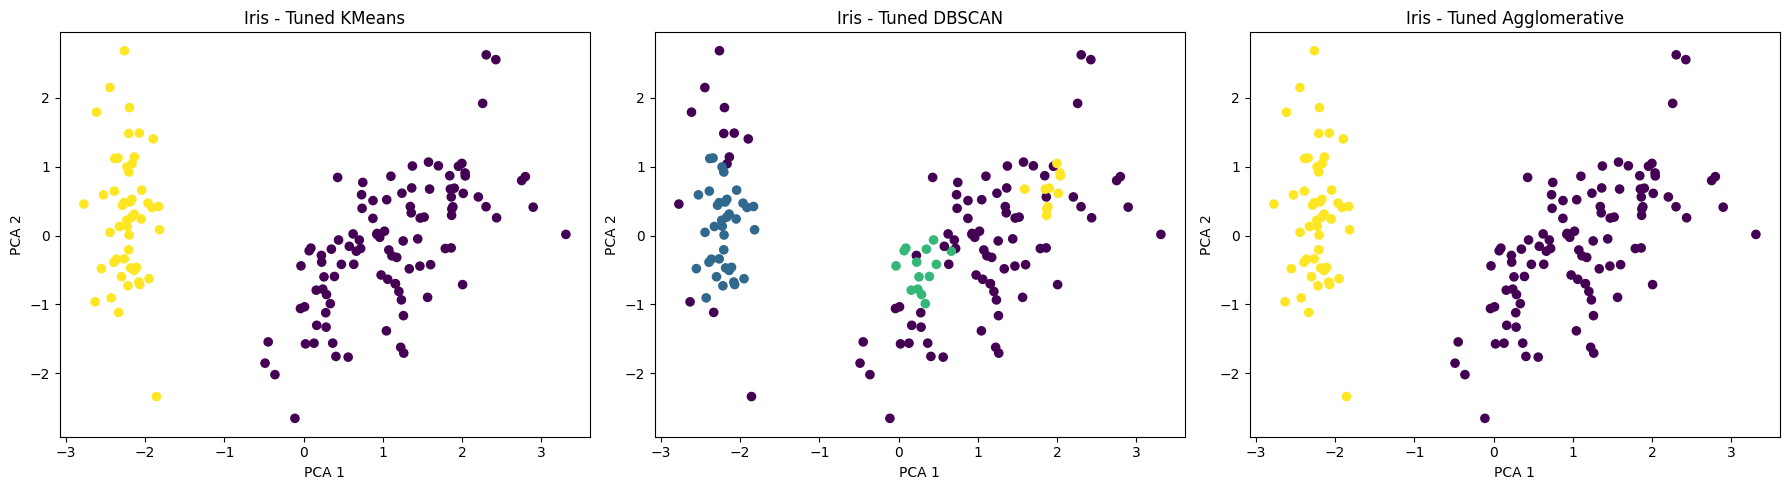

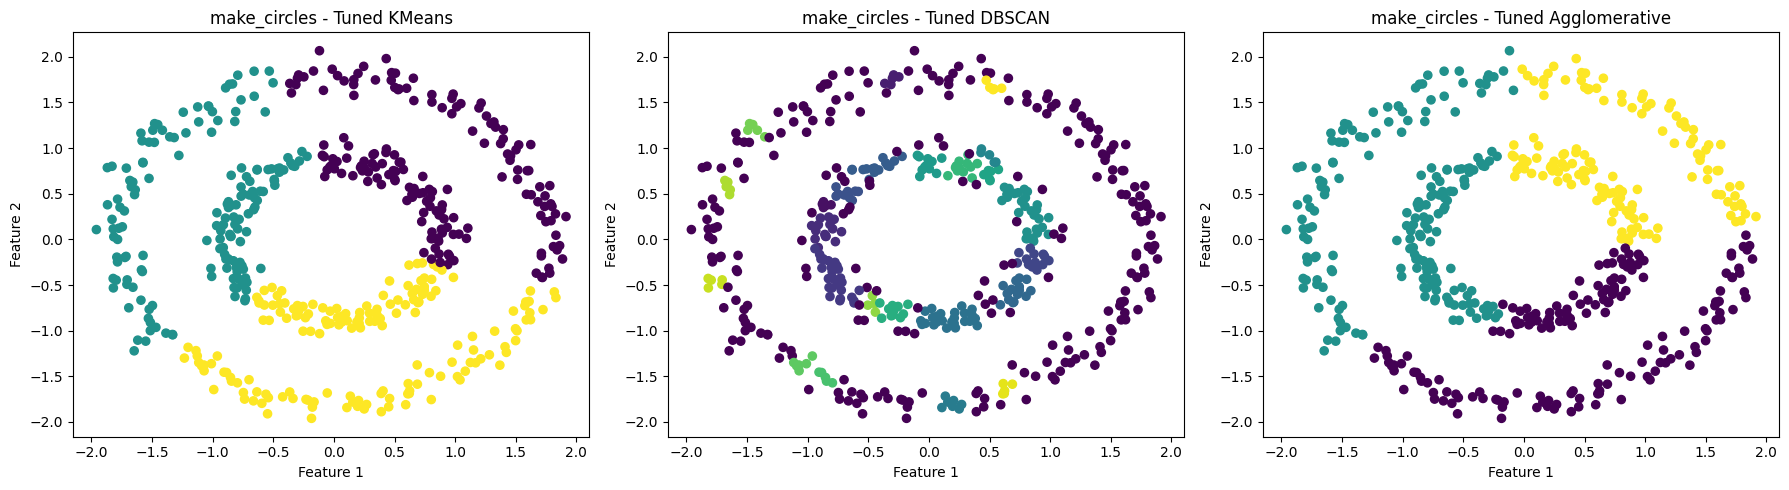

In [ ]:

# 調校後分群結果視覺化

# Iris 資料集
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, model) in zip(
    axes, iris_best_models.items()
):
    labels = model.fit_predict(iris_cluster_X_scaled)

    ax.scatter(
        iris_cluster_2d[:, 0],
        iris_cluster_2d[:, 1],
        c=labels,
        cmap="viridis",
        s=35
    )

    ax.set_title(f"Iris - Tuned {model_name}")
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")

plt.tight_layout()
plt.show()


# make_circles 資料集
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, model) in zip(
    axes, circles_best_models.items()
):
    labels = model.fit_predict(circles_X_scaled)

    ax.scatter(
        circles_X_scaled[:, 0],
        circles_X_scaled[:, 1],
        c=labels,
        cmap="viridis",
        s=35
    )

    ax.set_title(f"make_circles - Tuned {model_name}")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()